**## Import Libraries**

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

print("Libraries imported successfully!")


Libraries imported successfully!


**## Upload Dataset**

In [ ]:
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore (1).csv


**## Read Dataset**

In [ ]:
filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding='latin-1')

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


**## Dataset Information**

In [ ]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 

**## Check Missing Values**

In [ ]:

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total Missing Values: 0


**## Check Duplicate Records**

In [ ]:

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)


Number of Duplicate Rows: 0


**## Prepare Sales Data**

In [ ]:

required_columns = ["Product Name", "Sales"]

if not all(col in df.columns for col in required_columns):
    raise ValueError(
        "Dataset must contain 'Product Name' and 'Sales' columns. "
        f"Available columns: {df.columns.tolist()}"
    )

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

sales_df = df.dropna(subset=["Product Name", "Sales"]).copy()

print("Sales data prepared successfully!")
print("Rows available for analysis:", len(sales_df))


Sales data prepared successfully!
Rows available for analysis: 9994


**## Calculate Total Sales by Product**

In [ ]:

product_sales = (
    sales_df.groupby("Product Name", as_index=False)
    .agg(Total_Sales=("Sales", "sum"))
    .sort_values("Total_Sales", ascending=False)
)

print("Total sales calculated for each product.")
print("Unique products:", product_sales["Product Name"].nunique())

product_sales.head()


Total sales calculated for each product.
Unique products: 1850


,Product Name,Total_Sales
404,Canon imageCLASS 2200 Advanced Copier,61599.824
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480
786,HON 5400 Series Task Chairs for Big and Tall,21870.576
686,GBC DocuBind TL300 Electric Binding System,19823.479


**## Identify Top 10 Products**

In [ ]:

top_10_products = product_sales.head(10).copy()
top_10_products["Total_Sales"] = top_10_products["Total_Sales"].round(2)

print("Top 10 Products by Sales")
top_10_products


Top 10 Products by Sales


,Product Name,Total_Sales
404,Canon imageCLASS 2200 Advanced Copier,61599.82
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48
786,HON 5400 Series Task Chairs for Big and Tall,21870.58
686,GBC DocuBind TL300 Electric Binding System,19823.48
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
805,Hewlett Packard LaserJet 3310 Copier,18839.69
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
683,GBC DocuBind P400 Electric Binding System,17965.07
813,High Speed Automatic Electric Letter Opener,17030.31


**## Create Bar Chart**

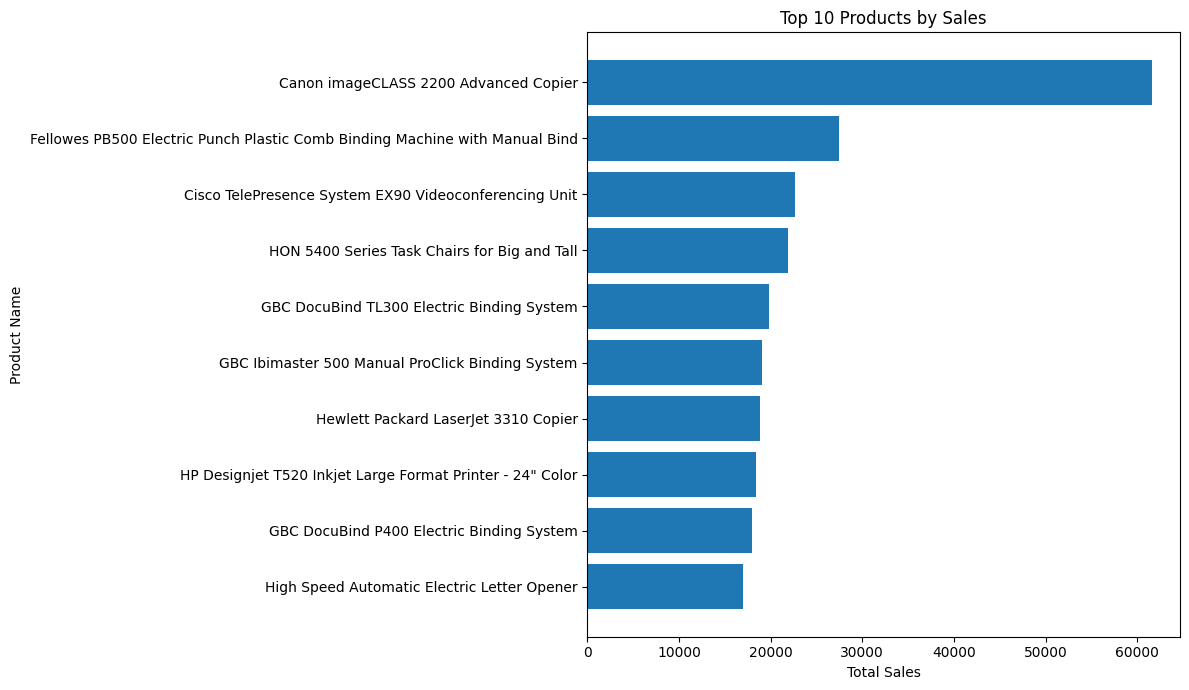

In [ ]:

if top_10_products.empty:
    print("No product sales data available to plot.")
else:
    chart_data = top_10_products.sort_values("Total_Sales")

    plt.figure(figsize=(12, 7))
    plt.barh(
        chart_data["Product Name"],
        chart_data["Total_Sales"]
    )

    plt.xlabel("Total Sales")
    plt.ylabel("Product Name")
    plt.title("Top 10 Products by Sales")
    plt.tight_layout()
    plt.show()


**## Display Top Product**

In [ ]:

if not top_10_products.empty:
    best_product = top_10_products.iloc[0]

    print("Best-Selling Product:", best_product["Product Name"])
    print("Total Sales:", round(best_product["Total_Sales"], 2))


Best-Selling Product: Canon imageCLASS 2200 Advanced Copier
Total Sales: 61599.82


**## Export Top 10 Results**

In [ ]:

output_file = "Task_17_Top_10_Products.csv"

top_10_products.to_csv(output_file, index=False)

print("Results saved successfully!")
print("Output file:", output_file)
print("Number of products exported:", len(top_10_products))


Results saved successfully!
Output file: Task_17_Top_10_Products.csv
Number of products exported: 10


**## Download Results**

In [ ]:

files.download(output_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>